# GATE (Sinogram Reconstruction; No Time of Flight)

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("PET/GATE-mMR-BrainInWater")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("PET/GATE-mMR-BrainInWater")

PET/GATE-mMR-BrainInWater: already downloaded


In [2]:
from __future__ import annotations
import torch
import numpy as np
import pytomography
from pytomography.metadata import ObjectMeta
from pytomography.metadata.PET import PETSinogramPolygonProjMeta
from pytomography.projectors.PET import PETSinogramSystemMatrix
from pytomography.algorithms import OSEM
from pytomography import io
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.utils import sss
from pytomography.transforms.shared import GaussianFilter
import matplotlib.pyplot as plt

## How much memory this needs

Set `RAM_GB` to the memory this tutorial may use, and pass it to `pytomography.set_memory_budget`. The steps that go through all 411 million crystal pairs of the scanner (the normalization sinogram) and the binning of the events then work in blocks that fit, and each sinogram (1.65 GB) is freed after its last use. Each reconstruction and the scatter estimate print their estimates before they run (`estimate_memory`). The tutorial peaks at about 18 GB (measured on Windows), the same with `RAM_GB = 12`, so it does not fit in 16 GB whatever `RAM_GB` is: its additive terms and reconstructions hold whole sinograms, which the budget does not split yet. The results do not depend on the budget.

In [3]:
RAM_GB = 25 # memory (RAM) this tutorial may use, in GB; it needs about 18 GB however low this is
pytomography.set_memory_budget(RAM_GB)

Reading the ROOT files takes a few minutes for each kind of coincidence, so the reader below keeps each result in `OUTPUT`, and later runs of this tutorial load it from there:

In [4]:
# The first run reads the ROOT files and caches each result in OUTPUT; later runs load the cache.
# Set this to True to recompute everything.
LOAD_FROM_ROOT = False

`io.PET.read_gate` reads the simulation: the scanner from its GATE macro, and the coincidences from its 54 ROOT files. It returns the events (pairs of crystal numbers, and a TOF bin when asked for), the object grid placed in the patient, and the projection metadata, whose `info` describes the scanner for every PET function in PyTomography. GATE's world has no patient in it; the dataset registry records how the phantom sat in it, and `read_gate` uses that for this dataset, so the images line up with the phantom's MR.

In [5]:
path = DATA / 'PET' / 'GATE-mMR-BrainInWater'
macro = path / 'mMR_Geometry.mac'  # the scanner, as the simulation's GATE macro describes it
paths = [path / 'simple_phantom' / f'mMR_voxBrain_withSimplePhantom_{i}.root' for i in range(1, 55)]  # its 54 runs


def read_gate(events, tof_meta=None, normalization=None):
    """io.PET.read_gate for one kind of coincidence: (events, object_meta, proj_meta). Reading the 54 ROOT files takes
    a few minutes, so the first run keeps the result in OUTPUT and later runs load it from there."""
    name = f'gate_{events}' + ('' if tof_meta is None else f'_tof{tof_meta.num_bins}') + ('' if normalization is None else '_norm')
    cache = OUTPUT / f'{name}.pt'
    if LOAD_FROM_ROOT or not cache.exists():
        # doi: the lines of response end 9 mm inside the crystals, the mean depth of interaction
        torch.save(io.PET.read_gate(paths, macro, events=events, tof_meta=tof_meta, normalization=normalization,
                                    doi=9), cache)
    return torch.load(cache, weights_only=False)


# The true coincidences (used from "Primary-Only Reconstruction" on), with the normalization weights of every crystal
# pair (below). proj_meta.info describes the scanner
detector_ids, object_meta, proj_meta = read_gate('trues', normalization=path / 'normalization_weights.npy')
info = proj_meta.info

We can look at the information of our PET scanner:

In [6]:
info

{'crystalTransNr': 8,
 'crystalAxialNr': 8,
 'submoduleTransNr': 1,
 'submoduleAxialNr': 1,
 'moduleTransNr': 1,
 'moduleAxialNr': 8,
 'rsectorTransNr': 56,
 'rsectorAxialNr': 1,
 'crystalTransSpacing': 4.0,
 'crystalAxialSpacing': 4.0,
 'submoduleTransSpacing': 0.0,
 'submoduleAxialSpacing': 0.0,
 'moduleTransSpacing': 0.0,
 'moduleAxialSpacing': 32.25,
 'rsectorAxialSpacing': 0.0,
 'radius': 337.0,
 'doi': 9.0,
 'crystal_length': 20.0,
 'min_rsector_difference': 0,
 'rsector0_angle': 0.0,
 'transaxial_direction': 1,
 'axial_direction': -1,
 'energy_window_low': None,
 'energy_window_high': None,
 'energy_resolution': None,
 'NrCrystalsPerRing': 448,
 'NrRings': 64}

## Normalization Correction

In PET imaging, each detector crystal used in the scanner will have a different response to a uniform source due to its positioning (e.g. crystals at the end of edge of modules are different than those in the center). Adequate PET reconstruction takes this into account by first performing a calibration scan for a scanner and obtaining a normalization correction factor for each crystal pair LOR

The normalization weights corresponding to each pair of detector IDs (due to geometry/crystal orientation) come with the dataset, in `normalization_weights.npy`. `read_gate` takes them as `normalization=` and keeps them in `proj_meta.weights_sensitivity`; the 89 million pairs whose lines of response miss the calibration shell have no weight in the file (NaN), and `read_gate` sets them to 0, with a warning. They were computed from a calibration scan done using a thin cylindrical shell, with `io.PET.gate_normalization`, which computes $\eta$ from the scan's ROOT files. For this it needs

* `cylinder_radius`: The radius of the thin cylindrical shell used for calibration (318 mm)

Randoms were left out of the scan (PyTomography PR #290). The scan itself (36 ROOT files, 46 GB) is in `PET/GATE-mMR-Brain/normalization_scan`, for anyone who wants to compute the weights again.

In [7]:
if LOAD_FROM_ROOT or not (OUTPUT / 'normalization_sinogram.pt').exists():
    # The weights come with the dataset. They were computed from the calibration scan (36 ROOT files, 46 GB, in
    # PET/GATE-mMR-Brain/normalization_scan), randoms left out (PyTomography PR #290):
    # normalization_weights = io.PET.gate_normalization(normalization_paths, info, cylinder_radius=318)
    torch.save(io.PET.normalization_sinogram(proj_meta.weights_sensitivity, info), OUTPUT / 'normalization_sinogram.pt')
normalization_sinogram = torch.load(OUTPUT / 'normalization_sinogram.pt')
proj_meta.weights_sensitivity = None  # the sinogram holds what the reconstructions need

## Primary-Only Reconstruction

Before we delve into scatter/random modeling, lets get a baseline reconstruction that uses only primary events from the simulated GATE data. PyTomography selected such events when it read the ROOT data above (`events='trues'`). Obviously this is not doable for clinical data (where we don't know which events are randoms/scatters). PyTomography always begins by opening listmode events that yield pairs of detector IDs for each detected event.

Lets also get the true scatters and randoms from this data so we can compare our estimation later on

In [8]:
detector_ids_randoms_true, _, _ = read_gate('randoms')
detector_ids_scatters_true, _, _ = read_gate('scatters')

We can convert the loaded listmode events into sinogram format using the following:
* Note: PyTomography currently only has basic sinogram binning functionality with no mashing / data reduction

In [9]:
sinogram = io.PET.listmode_to_sinogram(detector_ids, info)

We reconstruct as follows:

In [10]:
# The reconstruction grid: 128 x 128 x 96 voxels of 2 mm, centred where read_gate placed the scanner in the patient
object_meta = object_meta.with_grid(dr=(2, 2, 2), shape=(128, 128, 96))  # mm, voxels
# The phantom's attenuation map (1/cm), an image in GATE's world: gate_image places it in the patient as read_gate
# placed the scanner, and attenuation_map puts it on the grid, in 1/mm
atten_map = io.attenuation_map(io.PET.gate_image(path / 'umap_mMR_brainSimplePhantom.hv', proj_meta, units='1/cm'),
                               object_meta)
# Get projection space metadata from PET geometry information dictionary
proj_meta = PETSinogramPolygonProjMeta(info)
psf_transform = GaussianFilter(3) # 3mm gaussian blurring
# Create system matrix
system_matrix = PETSinogramSystemMatrix(
       object_meta,
       proj_meta,
       obj2obj_transforms = [psf_transform],
       sinogram_sensitivity = normalization_sinogram,
       N_splits=10, # Split FP/BP into 10 loops to save memory
       attenuation_map=atten_map,
       device='cpu' # projections are output on the CPU, but internal computation is on GPU
)
# Create likelihood
likelihood = PoissonLogLikelihood(
    system_matrix,
    sinogram,
)
# Initialize reconstruction algorithm
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=24)) # its peak RAM and GPU memory, before it runs
# Reconstruct
recon_primaryonly = recon_algorithm(n_iters=2, n_subsets=24)

OSEM (PETSinogramSystemMatrix): 24 subsets, memory budget 25 GB
Peak ~ 10.1 GB RAM, 1.2 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 3.3 GB RAM, 0.2 GB GPU (sensitivity sinogram 1.6 RAM, normalisation images (24) 0.2 GPU, image, update and attenuation map 0.03 GPU, projections (the data) 1.6 RAM)
  one subset at a time: 0.2 GB RAM, 0.00 GB GPU (data, expected counts, ratio and temporaries (one subset) 0.2 RAM)
  projector chunks: 0.00 GB RAM, 0.2 GB GPU (projector chunk 0.2 GPU)
  Python, CUDA, allocator: 5.4 GB RAM, 0.8 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.2 GPU, memory the allocators keep (Windows) 2.3 RAM)
To use less: 48 subsets ~ 10.0 GB RAM, 1.3 GB GPU, N_splits 20 ~ 9.9 GB RAM, 1.1 GB GPU
(plus whatever else your script keeps)


And plot:

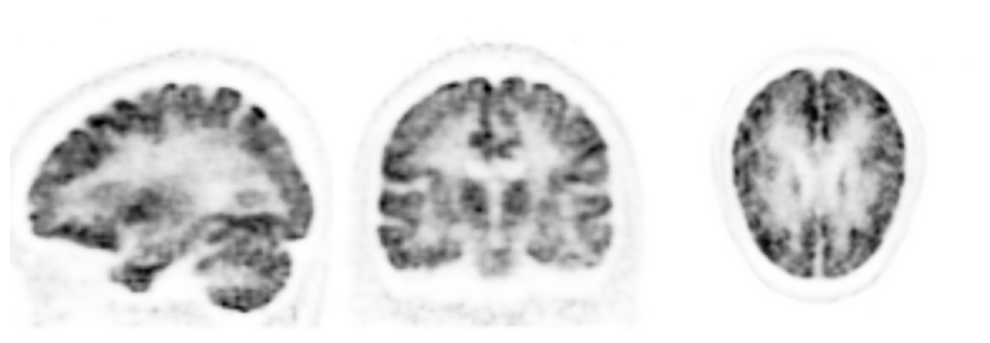

In [11]:
vmax = 0.45
cmap='Greys'
fig, ax = plt.subplots(1,3,figsize=(10,4), gridspec_kw={'wspace': 0.0})
plt.subplot(131)
plt.imshow(recon_primaryonly[50,16:-16].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
plt.subplot(132)
plt.imshow(recon_primaryonly[16:-16,64].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
plt.subplot(133)
plt.imshow(recon_primaryonly[:,:,48].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
fig.tight_layout()
plt.show()

Note that this is not possible in clinical practice, since we don't know which events are scatters/randoms. The reconstruction above is going to be used as an "ideal" comparison for our reconstruction of all events.

## Reconstruction Correcting For Randoms + Scatters

For reconstruction of all events, we need to estimate boths randoms and scatters. Lets now get **all** events that were obtained in GATE:

In [12]:
# The primary-only reconstruction is done: free its sinogram, likelihood and algorithm before binning all the events
del sinogram, likelihood, recon_algorithm
detector_ids, _, _ = read_gate('prompts')

Load the sinogram of all events:

In [13]:
sinogram = io.PET.listmode_to_sinogram(detector_ids, info)
del detector_ids # the sinogram holds what the reconstructions need

### Randoms

PyTomography has functionality to estimate random events via delayed coincidences. We can obtained the delayed coincidence random events from GATE data as follows:

In [14]:
detector_ids_delays, _, _ = read_gate('delayeds')

In [15]:
sinogram_delays = io.PET.listmode_to_sinogram(detector_ids_delays, info)

Let's plot the sinogram of estimated randoms ($r-z$ plane corresponding to $\theta=0$ and a ring difference of 0)

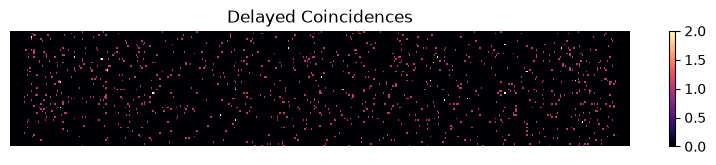

In [16]:
plt.figure(figsize=(10,1.5))
plt.pcolormesh(sinogram_delays[0,:,:64].T, cmap='magma')
plt.title('Delayed Coincidences')
plt.axis('off')
plt.colorbar()

As can be seen, the data is very sparse, and is not a good estimation of randoms in all bins. In order to make this a good estimation of randoms, we can smooth the sinogram:

In [17]:
sinogram_randoms_estimate = io.PET.smooth_randoms_sinogram(sinogram_delays, info, fwhm_r=20, fwhm_theta=7, fwhm_z=40)
del sinogram_delays # only the smoothed estimate is used from here on

Let's look at the interpolated sinogram, and compare it to the real randoms:

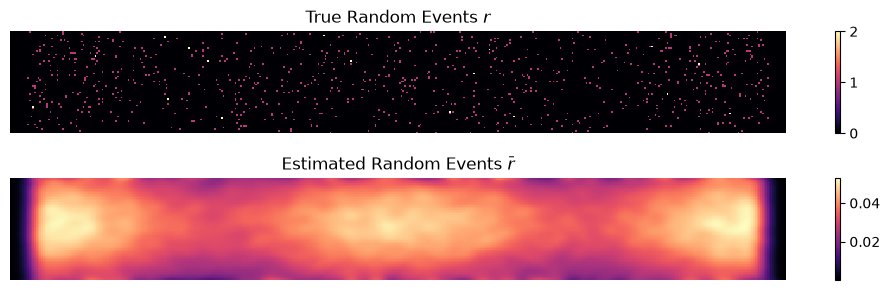

In [18]:
sinogram_randoms_true = io.PET.listmode_to_sinogram(detector_ids_randoms_true, info)

fig = plt.figure(figsize=(10,3))
plt.subplot(211)
plt.pcolormesh(sinogram_randoms_true[0,:,:64].T, cmap='magma')
plt.title('True Random Events $r$')
plt.axis('off')
plt.colorbar()
plt.subplot(212)
plt.pcolormesh(sinogram_randoms_estimate[0,:,:64].T, cmap='magma')
plt.title(r'Estimated Random Events $\bar{r}$')
plt.axis('off')
plt.colorbar()
fig.tight_layout()
plt.show()

# Delete to save memory
del sinogram_randoms_true, detector_ids_randoms_true

Note that the delayed coincidences are intended to yield the mean random rate $\bar{r}$ in each bin; the top plot yields a particular noise realization.

### Scatters

PyTomography estimates scatters via the single scatter simulation (SSS) algorithm (w or w/o time of flight). In order to use SSS, we need an initial reconstruction of the data (without scatter estimation). We use this reconstruction as a proxy to estimate scatter. Let's first reconstruct the data without scatter estimation (but using randoms):

In [19]:
# The same attenuation map and normalization sinogram as above
proj_meta = PETSinogramPolygonProjMeta(info)
psf_transform = GaussianFilter(3)
system_matrix = PETSinogramSystemMatrix(
       object_meta,
       proj_meta,
       obj2obj_transforms = [psf_transform],
       sinogram_sensitivity = normalization_sinogram,
       N_splits=10,
       attenuation_map=atten_map,
       device='cpu' # projections output on cpu, rest is GPU
)

We'll reconstruct only using randoms as an estimate. We need to pass the random sinogram estimate divided by the sensitivty sinogram as an additive term estimate to the likelihood function:

In [20]:
additive_term = sinogram_randoms_estimate / system_matrix._compute_sensitivity_sinogram().cpu()
likelihood = PoissonLogLikelihood(
        system_matrix,
        sinogram,
        additive_term = additive_term
    )

Now we reconstruct using only random estimation

In [21]:
recon_algorithm = OSEM(likelihood)
recon_without_scatter_estimation = recon_algorithm(2,24)
# The likelihood keeps its additive term, a whole sinogram; the scatter estimate below needs only the system matrix
del likelihood, recon_algorithm, additive_term

This reconstruction is then used to estimate scatter in the SSS scatter estimation technique. The parameters are discussed below the code cell below

In [22]:
# its peak RAM and GPU memory, before it runs
print(sss.estimate_sss_memory(object_meta, proj_meta, system_matrix, proj_data=sinogram,
                              sinogram_random=sinogram_randoms_estimate, sinogram_interring_stepsize=4,
                              sinogram_intraring_stepsize=4))
sinogram_scatter = sss.get_sss_scatter_estimate(
    object_meta = object_meta,
    proj_meta = proj_meta,
    pet_image = recon_without_scatter_estimation,
    attenuation_image = atten_map,
    system_matrix = system_matrix,
    proj_data = sinogram,
    image_stepsize = 4,
    attenuation_cutoff = 0.004,
    sinogram_interring_stepsize = 4,
    sinogram_intraring_stepsize = 4,
    sinogram_random = sinogram_randoms_estimate
    )

Single scatter simulation (dense)
Peak ~ 25.6 GB RAM, 6.5 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 8.2 GB RAM, 0.01 GB GPU (PET image and attenuation map 0.01 GPU, data 1.6 RAM, randoms 1.6 RAM, system matrix's sensitivity sinogram 1.6 RAM, interpolated estimate (dense) and its scaled copy (host) 3.3 RAM)
  projector chunks: 0.2 GB RAM, 4.3 GB GPU (largest step on the host: sparse estimate 0.2 RAM, sparse estimate (GPU) 0.2 GPU, interpolation over angle and radius (GPU) 0.7 GPU, interpolation over the ring pairs (GPU) 1.5 GPU, scaling (20 subsets) (GPU) 1.9 GPU)
  Python, CUDA, allocator: 10.7 GB RAM, 2.2 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 1.5 GPU, memory the allocators keep (Windows) 7.6 RAM)
(plus whatever else your script keeps)


Besides the obvious parameters:

* `pet_image` is the initial activity estimation which is used to estimate the scatter contribution. Note that although the activity is much higher here than the scatter-corrected image, the scatter is not over predicted since it is scaled to the tails at the end (discussed below)
* `attenuation_image` is used to compute compton cross sections
* `system_matrix` is needed for the scaling of the scatter tails.
* `proj_data` is required for the scaling of the scatter tails.
* `image_stepsize` is the stepsize in x/y/z used for subsampling voxels in object space for the scatter simulation.
* `attenuation_cutoff` is used for two purposes: (i) any scatter point below this value is not considered and (ii) when the attenuation map is forward projected as a mask to scale the scatter tails, this is the cutoff value for the mask
* `sinogram_interring_stepsize`: the axial (between rings) stepsize between detector crystals used as sample points in the scatter simulation
* `sinogram_intrraring_stepsize`: the transaxial stepsize between detector crystals used as sample points in the scatter simulation.
* `sinogram_random`: required for scaling the scatter tails at the end.

The SSS essentially works as follows: 

(i) Compute scatter estimation in sparse sinogram space (only certain detector crystals considered)
(ii) Interpolate sinogram
(iii) Scale scatter tails

Lets compare this to the true scatter distribution:



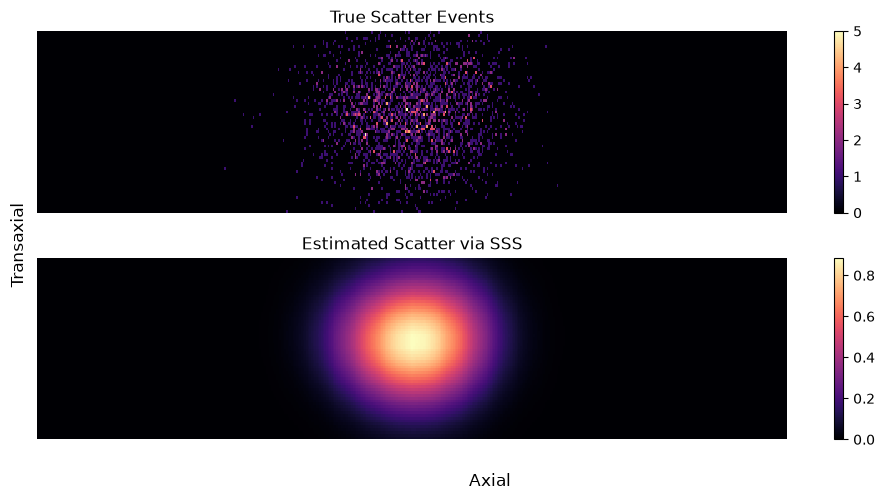

In [23]:
sinogram_scatters_true = io.PET.listmode_to_sinogram(detector_ids_scatters_true, info)

fig = plt.figure(figsize=(10,5))
plt.subplot(211)
plt.pcolormesh(sinogram_scatters_true[0,:,:64].T, cmap='magma')
plt.title('True Scatter Events')
plt.axis('off')
plt.colorbar()
plt.subplot(212)
plt.pcolormesh(sinogram_scatter[0,:,:64].T, cmap='magma')
plt.title('Estimated Scatter via SSS')
plt.axis('off')
plt.colorbar()
fig.supxlabel('Axial')
fig.supylabel('Transaxial')
fig.tight_layout()
plt.show()

It's a little hard to validate on the sinograms since the true scatter data is sparse. We can instead look at profiles by summing accross certain dimensions:

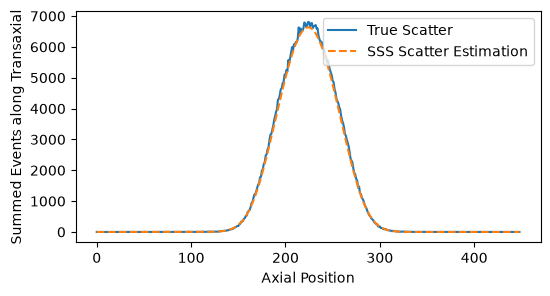

In [24]:
plt.figure(figsize=(6,3))
plt.plot(sinogram_scatters_true[:,:,:64].sum(dim=(0,2)), label='True Scatter')
plt.plot(sinogram_scatter[:,:,:64].sum(dim=(0,2)), ls='--', label='SSS Scatter Estimation')
plt.xlabel('Axial Position')
plt.ylabel('Summed Events along Transaxial')
plt.legend()
plt.show()
del sinogram_scatters_true, detector_ids_scatters_true # only needed for these plots

Now that we have the scatter sinogram estimate. The additive term to the likelihood is the sum of randoms+scatters divided by the sensitivty sinogram

In [25]:
additive_term = (sinogram_randoms_estimate + sinogram_scatter) / system_matrix._compute_sensitivity_sinogram().cpu()
likelihood = PoissonLogLikelihood(
        system_matrix,
        sinogram,
        additive_term = additive_term
    )
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=24))
recon_sinogram_noTOF = recon_algorithm(2,24)

OSEM (PETSinogramSystemMatrix): 24 subsets, memory budget 25 GB
Peak ~ 12.7 GB RAM, 1.2 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 4.9 GB RAM, 0.2 GB GPU (sensitivity sinogram 1.6 RAM, normalisation images (24) 0.2 GPU, image, update and attenuation map 0.03 GPU, projections (the data) 1.6 RAM, additive term 1.6 RAM)
  one subset at a time: 0.2 GB RAM, 0.00 GB GPU (data, expected counts, ratio and temporaries (one subset) 0.2 RAM)
  projector chunks: 0.00 GB RAM, 0.2 GB GPU (projector chunk 0.2 GPU)
  Python, CUDA, allocator: 6.4 GB RAM, 0.8 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.2 GPU, memory the allocators keep (Windows) 3.3 RAM)
To use less: 48 subsets ~ 12.6 GB RAM, 1.3 GB GPU, N_splits 20 ~ 12.5 GB RAM, 1.1 GB GPU
(plus whatever else your script keeps)


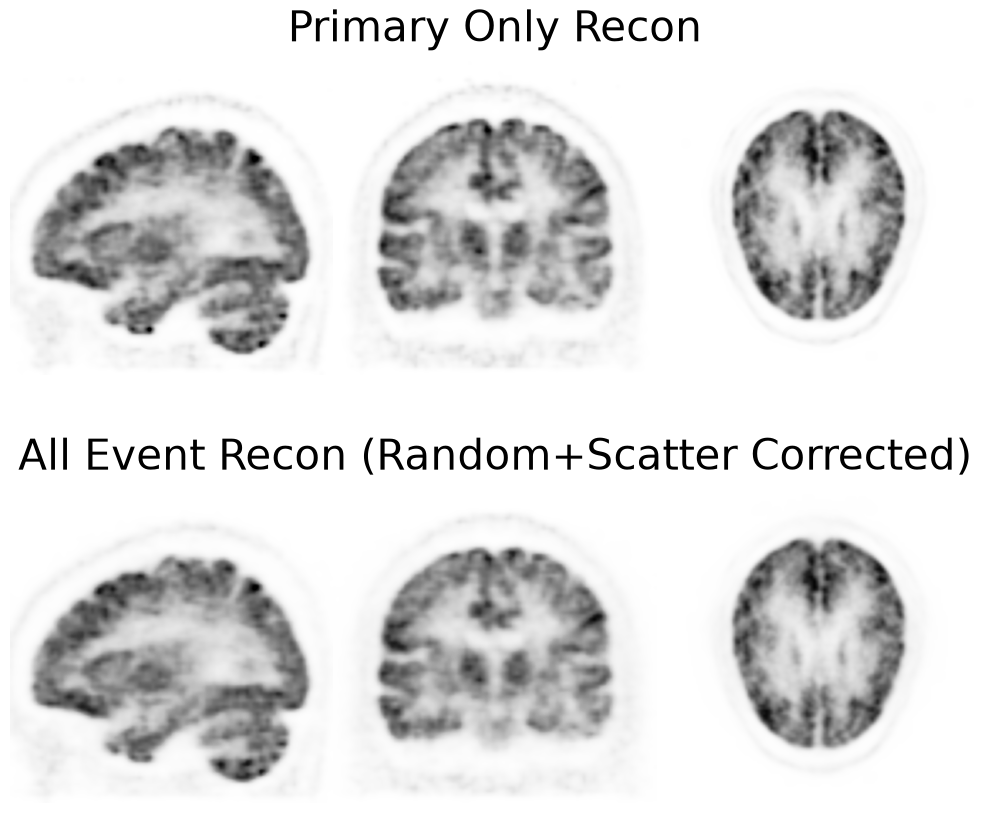

In [26]:
vmax = 0.45
cmap = 'Greys'
fig, ax = plt.subplots(2,3,figsize=(10,9), gridspec_kw={'wspace': 0.0})
plt.subplot(231)
plt.imshow(recon_primaryonly[48,16:-16].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(232)
plt.imshow(recon_primaryonly[16:-16,64].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.title('Primary Only Recon', fontsize=30)
plt.axis('off')
plt.subplot(233)
plt.imshow(recon_primaryonly[:,:,48].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(234)
plt.imshow(recon_sinogram_noTOF[48,16:-16].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(235)
plt.imshow(recon_sinogram_noTOF[16:-16,64].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.title('All Event Recon (Random+Scatter Corrected)', fontsize=30)
plt.subplot(236)
plt.imshow(recon_sinogram_noTOF[:,:,48].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
fig.tight_layout()
plt.show()
plt.show()

## Save the images

`io.save_dicom` writes the reconstruction as a DICOM PET series, one file per slice, where `object_meta` places it. GATE data have no patient frame of their own: `read_gate` placed the grid on the phantom's MR, from the dataset registry's record of where the phantom sat in GATE's world, so it lines up with that NIfTI file in software that reads both, such as 3D Slicer.

In [27]:
saved = io.save_dicom(recon_sinogram_noTOF, OUTPUT / 't_PETGATE_scat_sino' / 'osem', object_meta,
                      series_description='OSEM, scatter and randoms corrected', overwrite=True)

In [28]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 1.53, "peak_ram_gb": 17.9}
